In [10]:
import pennylane as qml
from pennylane import numpy as np
from matplotlib import pyplot as plt
import csv

Se implementa el método implícito de Euler, que resuelve ecuaciones de la forma

$\frac{dy}{dx} = f(x,y)$

con condición inicial $(x_0, y_0)$ y tamaño de paso $h$. El método aplica estas dos fórmulas iterativas:

$x_{n+1} = x_n + h$

$y_{n+1} = y_n + h \cdot f(x_n, y_n)$

Lo aplicaremos para resolver la ecuación

$\frac{dy}{dx} = y - k y^2$

que se corresponde con la ecuación tipo modelo logístico.

Elegimos k = 0.2

Este algoritmo es un ejemplo de "matar moscas a cañonazos". En efecto, se están utilizando los qubits como bits, y estamos limitados a trabajar con números que se puedan expresar con esa cierta cantidad de qubits, pero solo podemos usar un número pequeño de qubits, pues simularlos produce un gasto exponencial de memoria.

In [ ]:
n_qubits = 6
#precision = 2  esto es un remanente de algo mio

h = 0.1
x0 = -3
y0 = 0.8

def func(x : float, y : float) -> float:
    return y - 0.2 * y**2 

f = 1   # bits fraccionales
S = 2**f

def float_to_fixed(x):
    val = int(round(x * S))
    return val & ((1 << n_qubits) - 1)

def fixed_to_float(X):
    if X >= 2**(n_qubits-1):
        X -= 2**n_qubits
    return X / S


wires = qml.registers({"A": n_qubits-2, "B" : n_qubits, "work" : n_qubits, "output" : n_qubits})
def product_basis_state(A=0,B=0):
    #x es un numero entero (base 10) que se traduce a binario y se codifica en los wires que corresponden a "x"
    qml.BasisState(A, wires=wires["A"])
    #Lo mismo para y
    qml.BasisState(B, wires=wires["B"])

dev = qml.device("default.qubit")
@qml.set_shots(1)
@qml.qnode(dev)
def circuit(x,y,fun,h):

    product_basis_state(A=y, B=fun)
    #x=float_to_int(int_to_float(x, val, f), val, f)
    """ qml.BasisState(x, wires=wires["x"])
    qml.BasisState(y, wires=wires["y"]) """

    qml.Multiplier(float_to_fixed(h), wires["B"], work_wires= wires["work"])
    qml.OutAdder(wires["A"], wires["B"], wires["output"])
    out = qml.sample(wires=wires["output"])
    #out = state_to_decimal(out[0])
    #out = int_to_float(circuit,vmin,f)
    return out

    #return {name: qml.sample(wires=wires[name]) for name in ["x", "y", "output"]}

def state_to_decimal(binary_array):
    # Convert a binary array to a decimal number
    return sum(bit * (2 ** idx) for idx, bit in enumerate(reversed(binary_array)))

def QAeuler(x0, y0, step, steps, filename):
    x = x0
    y = y0

    for i in range(steps):
        filename.write(f"{i}\t{x:.4f}\t{y:.4f}\n")
        
        fun = float_to_fixed(func(x=x, y=y))
        y = float_to_fixed(y)
        x = float_to_fixed(x)

        #qml.Adder(y, wires["x"])
        #qml.Adder(f(x), wires["y"])
        y = circuit(x=x,y=y,fun=fun, h=step)
        print("----------")
        print("y = ", y)
        y = state_to_decimal(y[0])
        print(y)
        y = fixed_to_float(y)
        x = fixed_to_float(x)

        x = x+step

with open(file="quantumeuler.txt", mode="w") as myfile :
    pass
    #QAeuler(x0=x0, y0=y0, step=h, steps=30, filename=myfile)
    QAeuler(x0,y0,0.5,6,myfile)
    QAeuler(x0,y0,-0.5,6,myfile)



BUENOS DIAS
y =  [[0 0 0 0 1 1]]
3
BUENOS DIAS
y =  [[0 0 0 1 0 1]]
5
BUENOS DIAS
y =  [[0 0 0 1 1 1]]
7
BUENOS DIAS
y =  [[0 0 1 0 0 1]]
9
BUENOS DIAS
y =  [[0 0 1 0 1 0]]
10
BUENOS DIAS
y =  [[0 0 1 0 1 0]]
10
BUENOS DIAS
y =  [[0 0 0 0 0 1]]
1
BUENOS DIAS
y =  [[0 0 0 0 0 0]]
0
BUENOS DIAS
y =  [[0 0 0 0 0 0]]
0
BUENOS DIAS
y =  [[0 0 0 0 0 0]]
0
BUENOS DIAS
y =  [[0 0 0 0 0 0]]
0
BUENOS DIAS
y =  [[0 0 0 0 0 0]]
0


(12, 3)


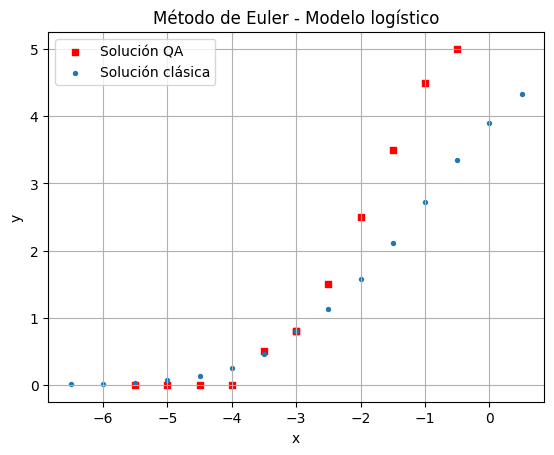

In [43]:
data = np.genfromtxt("quantumeuler.txt")
data2 = np.genfromtxt("euler_logistic.txt")
print(data.shape)

# Separar columnas
iteration = data[:,0]  # primera columna
x = data[:,1]          # segunda columna
y = data[:,2]          # tercera columna

x2= data2[:,1]          # segunda columna
y2 = data2[:,2]     


# Plotear
plt.close("all")
plt.figure()
plt.scatter(x, y, label="Solución QA", marker="s", c="r", s=14)
plt.scatter(x2, y2, label="Solución clásica", s=8)


plt.xlabel("x")
plt.ylabel("y")
plt.title("Método de Euler - Modelo logístico")
plt.legend()
plt.grid()
plt.show()

# c = 2
# c = float_to_int(c, vmin, f)
# c = int_to_float(c, vmin, f)
# print(c)